[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/11_Vulnerability_Software_Supply_Chain_Attacks/RQENN_VulnerabilityDetection_Song2024.ipynb)

# RQENN for vulnerability detection: Song et al. (2024) step by step

**Paper.** Zhihui Song, Xin Zhou, Jinchen Xu, Xiaodong Ding and Zheng Shan, *Recurrent quantum embedding neural network and its application in vulnerability detection*, Scientific Reports 14, 13642 (2024). DOI [10.1038/s41598-024-63021-y](https://doi.org/10.1038/s41598-024-63021-y).

**What this notebook does.** It rebuilds the paper's *Recurrent Quantum Embedding Neural Network* (RQENN): a 7-qubit circuit whose single "cell" reads one source-code token at a time, so that a whole code gadget is processed like a sentence by a recurrent network. It
1. downloads the public VulDeePecker code-gadget database (C/C++ gadgets labelled vulnerable or not, CWE-119 and CWE-399),
2. normalises the code (VAR1, FUN1, ...), tokenises it, builds a 128-entry dictionary and turns every token into a *parameterised binary index*,
3. trains the RQENN with an **exact, differentiable state-vector simulator** and proves that this simulator equals the real PennyLane circuit,
4. trains a classical RNN, an LSTM, a Random Forest and an SVC on exactly the same inputs and folds,
5. repeats the paper's ablations (encoding method, number of layers, code length) and compares every number with the paper.

**How to run.** Colab, CPU runtime, *Runtime > Run all* (the first cell installs PennyLane; restart the session if Colab asks). No token or account is needed: the data are public files on GitHub. `FAST_MODE = False` took about 36 minutes on a lightly loaded laptop CPU (single thread, 83 minutes when the machine was heavily shared; this executed notebook is the 36-minute run); `FAST_MODE = True` gives a class demonstration in about 12 minutes (3-fold CV on lengths (40, 60]).

**What you get at the end.** Executed figures (data exploration, circuit drawings, learning curves, confusion matrices, ablations), a parameter-count table that matches the paper's Table 2 exactly, and a claim-by-claim verdict table.

## The paper in one page

**Problem.** Deep-learning vulnerability detectors treat code like text, but large NLP models need a lot of memory. The authors ask whether a *quantum* neural network with very few qubits and parameters can read code tokens.

**Decision.** Given a *code gadget* (a few program statements that are linked by data flow to a risky library call such as `strcat`), decide whether it contains a vulnerability (label 1) or not (label 0).

**Method (Figs. 1-3, Eqs. 1-11).**
- *Trainable encoding by parameterised binary index.* Every token gets an index in a dictionary of N = 128 words; its 7-bit binary form is turned into Ry rotation angles by replacing every bit 0 by the trainable angle theta_0 and every bit 1 by theta_1 (so only **2** input parameters). Bit i drives an Ry gate on qubit i.
- *QEmbedding layer* (m layers): per layer two rotation layers (7 Ry each) interleaved with two layers of staggered CNOTs: 14 parameters per layer, the quantum analogue of a word-embedding matrix.
- *QWeight layer* (n layers): a chain of six two-qubit unitaries (two Ry and one CNOT each), 12 parameters per layer, the quantum analogue of the recurrent weight matrix.
- *Recurrence.* The state starts as H^7|0>; at every time step the same cell U_qnn U_qe U_in(x_t) is applied (shared parameters). After the last token the expectation values of Z on the last two qubits are the two class logits, trained with cross-entropy.
- With m = n = 4 the model has 2 + 56 + 48 = **106** parameters (Table 2) against 49,666 for an RNN with 128-dimensional embedding and hidden state.

**Data.** Code gadgets of Li et al. (VulDeePecker, NDSS 2018; NVD and SARD; buffer-error and resource-management vulnerabilities). The authors regenerate normalised gadgets with Joern, select about 5000 gadgets balanced over six token-length intervals (40, 50] ... (90, 100] and evaluate with 5-fold cross-validation, batch size 64, Adam (lr 0.01), 10 epochs, accuracy as the metric; they report the *best* test accuracy over the epochs.

**Claims checked here.** (i) 106 vs 49,666 parameters, 7 qubits; (ii) m = n = 4 gives 87.4% best test accuracy (median) on the full set (Fig. 5); parameterised binary index 87.4% vs orthogonal 80.2% vs plain binary 77.8% (Fig. 6); (iii) RQENN 85.4% vs RNN 86.1% (Fig. 7), LSTM 89.7%; (iv) RQENN is better than the RNN for short code (T <= 80) and worse for long code (Fig. 8, Table 3, e.g. 99.0% at T = 50, 92.0% at T = 60); (v) 15.7 points above QLSTM (cannot be checked, see below).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Source of the code gadgets | gadgets regenerated with Joern from the NVD/SARD programs; data "available on request" | the **published VulDeePecker CGD files** (61,638 gadgets, the same NVD/SARD programs and gadget definition) from GitHub; no Joern re-extraction |
| Normalisation | remove comments and strings, VAR1.. / FUN1.. renaming | same; the list of library/API names that stay unrenamed is not given, so a compact libc/POSIX/Win32 list is used (`# CHOICE`) |
| Tokenisation | punctuation removed, split, padded | regex tokeniser that keeps operators and punctuation as tokens; this reproduces the paper's length statistics (mean about 70 tokens in (40, 100]) |
| Evaluation set | about 5000 gadgets, six intervals (40, 100], balanced | 417 safe + 417 vulnerable per interval = 5004 (FULL); FAST_MODE uses only (40, 60] |
| Duplicates | not mentioned | kept (`DEDUP = False`); half of the test gadgets have an exact copy in the training split, reported below and discussed critically |
| Dictionary / padding | 128 entries, padded to T | 126 most frequent training tokens + PAD (index 0) + UNK (index 1); padding in front; dictionary fitted on each training split only |
| Initial angles | not given | N(0, 0.1^2) for circuit angles, theta_0 = 0 and theta_1 = 1 (the plain binary index) for the trainable input angles (`# CHOICE`) |
| Class logits | expectation of Z on the last two qubits | class 0 <- <Z_5>, class 1 <- <Z_6> (the order is not stated) |
| Simulator | MindQuantum | exact real-amplitude state-vector simulator in PyTorch (autograd gradients) and PennyLane `default.qubit` for the drawing and the equality check |
| Optimiser | Adam, lr 0.01, batch 64, 10 epochs, cross-entropy | same |
| Metric | best test accuracy over the epochs (median over 5 folds) | the same *and* the final-epoch accuracy, because picking the best epoch on the test fold is optimistic |
| Classical RNN | embedding 128, hidden 128 (49,666 parameters) | `nn.Embedding(128,128)` + `nn.RNN(128,128)` + `nn.Linear(128,2)`: exactly 49,666 parameters |
| DisCoCat, QLSTM, BERT | compared in Table 3 / Discussion | **not implemented** (lambeq needs an extra framework; QLSTM has no public code in the paper): verdict "cannot be checked" |
| Hardware | simulator only | simulator only (`IBM_TOKEN` is unused) |

## 0. Setup

PyTorch, NumPy, pandas, scikit-learn and matplotlib are preinstalled on Colab; only PennyLane has to be added (pinned to the version tested here). The configuration cell holds every tunable constant. With `FAST_MODE = True` the notebook uses only gadgets of length (40, 60] and fewer folds so that it finishes in a few minutes on a CPU; the full budgets of the paper are in the `else` branch.

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and PyTorch.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane already present; skipping pip install.")


PennyLane already present; skipping pip install.


In [2]:
SEED = 42
FAST_MODE = False            # True: class demo on lengths (40, 60] (a few minutes of CPU); False: the paper's budgets (many hours on a CPU simulator)
N_QUBITS = 7                # = ceil(log2(DICT_SIZE)): one qubit per bit of the token index
DICT_SIZE = 128             # paper: dictionary of 128 tokens
LR = 0.01                   # paper: Adam, learning rate 0.01
BATCH = 64                  # paper: batch size 64
M_LAYERS = N_LAYERS = 4     # paper: best RQENN has m = 4 QEmbedding and n = 4 QWeight layers
INIT_STD = 0.1              # CHOICE: all circuit angles start as N(0, 0.1^2) (the paper does not give its initialisation)
THETA_IN_INIT = (0.0, 1.0)  # CHOICE: the trainable theta_0, theta_1 start at the plain binary-index values 0 and 1
DEDUP = False               # CHOICE: True removes duplicate gadgets (the paper does not mention it); see the leakage check below
IBM_TOKEN = ""              # not used: this notebook runs on exact simulators only
DATA_DIR = "vdp_data"       # downloaded files are cached here (public GitHub files, no token needed)
USE_LOCAL_FILES = False     # True + LOCAL_DIR: read cwe119_cgd.txt / cwe399_cgd.txt from a local folder instead of downloading
LOCAL_DIR = ""

if FAST_MODE:
    INTERVALS = [(40, 50), (50, 60)]                         # token-length intervals (lo, hi], T = hi
    N_PER_CLASS_PER_INTERVAL = 300                           # gadgets per class and interval (paper: about 417)
    N_FOLDS, EPOCHS = 3, 10                                  # paper: 5-fold CV, 10 epochs
    ABL_FOLDS, GRID, IV_FOLDS = 1, [(1, 1), (2, 2)], 1       # folds used by the ablation / layer grid / interval study; (m, n) grid
else:
    # Paper-scale data and training; the ablations are trimmed to what a CPU simulator can do in about two hours in total.
    INTERVALS = [(40, 50), (50, 60), (60, 70), (70, 80), (80, 90), (90, 100)]
    N_PER_CLASS_PER_INTERVAL = 417                           # 6 x 2 x 417 = 5004 gadgets (paper: about 5000)
    N_FOLDS, EPOCHS = 5, 10                                  # as in the paper
    ABL_FOLDS, GRID, IV_FOLDS = 1, [(1, 1), (2, 2)], 1       # trimmed; the paper's budget is ABL_FOLDS = IV_FOLDS = 5 and
    # GRID = [(m, n) for m in range(1, 7) for n in range(1, 7)]  (36 architectures x 5 folds, several days of CPU time)
T_MAX = INTERVALS[-1][1]                                     # sequence length of the "full" set: longest token sequence
print(f"FAST_MODE={FAST_MODE}: lengths ({INTERVALS[0][0]}, {T_MAX}], {N_PER_CLASS_PER_INTERVAL} gadgets/class/interval, "
      f"{N_FOLDS}-fold CV, {EPOCHS} epochs, batch {BATCH}, lr {LR}")


FAST_MODE=False: lengths (40, 100], 417 gadgets/class/interval, 5-fold CV, 10 epochs, batch 64, lr 0.01


In [3]:
import os, sys, time, math, json, collections, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import sklearn, pennylane as qml

warnings.filterwarnings("ignore", message="Converting a tensor with requires_grad")
torch.set_num_threads(1)   # one thread: tiny matrices, and a small footprint on a shared machine
np.random.seed(SEED); torch.manual_seed(SEED); rng_global = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.25})
print("numpy", np.__version__, "| pandas", pd.__version__, "| torch", torch.__version__, "| scikit-learn", sklearn.__version__,
      "| pennylane", qml.__version__, "| matplotlib", matplotlib.__version__)


numpy 2.5.4 | pandas 3.0.6 | torch 2.14.1+cpu | scikit-learn 1.9.1 | pennylane 0.45.1 | matplotlib 3.11.2


## 1. Data: download, normalise, tokenise, select

The two VulDeePecker files hold *code gadgets*: a header line, the program statements, a label (1 = vulnerable) and a separator. We (a) parse them, (b) strip comments and strings, rename user functions to `FUN1, FUN2, ...` and variables to `VAR1, VAR2, ...` (so that the model learns the *structure* rather than identifier names), (c) tokenise, and (d) draw the paper's evaluation set: the same number of safe and vulnerable gadgets in every length interval (lo, hi], where the sequence length is T = hi.

In [4]:
import re, collections, requests, pandas as pd

CGD_URLS = {
    119: "https://raw.githubusercontent.com/CGCL-codes/VulDeePecker/master/CWE-119/CGD/cwe119_cgd.txt",
    399: "https://raw.githubusercontent.com/CGCL-codes/VulDeePecker/master/CWE-399/CGD/cwe399_cgd.txt",
}
DATA_DIR = Path(DATA_DIR); DATA_DIR.mkdir(parents=True, exist_ok=True)

def fetch(cwe):
    path = DATA_DIR / f"cwe{cwe}_cgd.txt"
    if USE_LOCAL_FILES and (Path(LOCAL_DIR) / path.name).exists():
        return Path(LOCAL_DIR) / path.name
    if not path.exists() or path.stat().st_size < 1_000_000:
        r = requests.get(CGD_URLS[cwe], timeout=120); r.raise_for_status()
        path.write_bytes(r.content)
    return path

SEPARATOR = "-" * 33
def parse_cgd(path, cwe):
    """VulDeePecker CGD format: header line, code lines, label line (0/1), then a line of 33 dashes."""
    recs, cur = [], []
    for line in open(path, encoding="utf8", errors="ignore"):
        line = line.rstrip("\n")
        if line.strip() == SEPARATOR:
            while cur and not cur[-1].strip():
                cur.pop()
            if len(cur) >= 3 and cur[-1].strip() in ("0", "1"):
                recs.append({"cwe": cwe, "label": int(cur[-1]), "header": cur[0], "code": "\n".join(cur[1:-1])})
            cur = []
        else:
            cur.append(line)
    return recs

raw = pd.DataFrame(parse_cgd(fetch(119), 119) + parse_cgd(fetch(399), 399))
print("raw code gadgets:", raw.shape, "| columns:", list(raw.columns))
print(raw.groupby(["cwe", "label"]).size().rename("gadgets").to_frame())

# ---- normalisation (paper Step I): remove comments and strings, rename user functions FUNk and variables VARk ----
C_KEYWORDS = set("""auto break case char const continue default do double else enum extern float for goto if inline int long
register restrict return short signed sizeof static struct switch typedef union unsigned void volatile while class public private
protected namespace new delete try catch throw this template typename using virtual bool true false NULL nullptr wchar_t size_t ssize_t
uint8_t uint16_t uint32_t uint64_t int8_t int16_t int32_t int64_t FILE std string cout cin endl main""".split())
# CHOICE: the paper keeps library / API names (it slices around them) but does not list them; this is a compact libc / POSIX / Win32 list.
API_NAMES = set("""malloc calloc realloc free alloca memcpy memmove memset memcmp memchr strcpy strncpy strcat strncat strlen strcmp strncmp strchr
strrchr strstr strdup strndup strtok strtol strtoul strtod sprintf snprintf vsprintf vsnprintf printf fprintf scanf sscanf fscanf gets fgets puts
fputs fopen fclose fread fwrite fseek ftell fflush getc putc fgetc fputc getchar putchar read write open close lseek recv recvfrom send sendto
socket bind listen accept connect select poll ioctl fcntl mmap munmap wcscpy wcsncpy wcscat wcsncat wcslen wcscmp swprintf wmemcpy wmemset
_snprintf _snwprintf StrCpy StrCat lstrcpy lstrcat lstrcpyn CopyMemory MoveMemory ZeroMemory RtlCopyMemory MultiByteToWideChar WideCharToMultiByte
HeapAlloc HeapFree VirtualAlloc VirtualFree LocalAlloc LocalFree GlobalAlloc GlobalFree CreateFile ReadFile WriteFile CloseHandle atoi atol atof
abs exit abort assert getenv setenv system popen pclose fork execl execv execve pthread_create pthread_mutex_lock pthread_mutex_unlock
rand srand time sleep usleep signal kill getpid getuid setuid strerror perror errno qsort bsearch toupper tolower isalpha isdigit isspace isalnum
isupper islower isprint gethostbyname getaddrinfo inet_addr inet_ntoa htons htonl ntohs ntohl tmpfile mkstemp mktemp realpath getcwd chdir
stat fstat lstat unlink rename mkdir rmdir opendir readdir closedir va_start va_end va_arg new_array delete_array""".split())

TOKEN_RE = re.compile(r"[A-Za-z_]\w*|\d+\.?\d*|==|!=|<=|>=|->|\+\+|--|&&|\|\||<<|>>|\+=|-=|\*=|/=|[^\sA-Za-z_\d]")
def strip_comments_strings(code):
    code = re.sub(r"/\*.*?\*/", " ", code, flags=re.S)
    code = re.sub(r"//[^\n]*", " ", code)
    code = re.sub(r'"(\\.|[^"\\])*"', '""', code)
    code = re.sub(r"'(\\.|[^'\\])*'", "''", code)
    return code

def normalise(code):
    toks = TOKEN_RE.findall(strip_comments_strings(code))
    fun, var, out = {}, {}, []
    for i, t in enumerate(toks):
        if re.match(r"[A-Za-z_]\w*$", t) and t not in C_KEYWORDS and t not in API_NAMES:
            is_call = i + 1 < len(toks) and toks[i + 1] == "("
            if is_call:
                t = fun.setdefault(t, f"FUN{len(fun) + 1}")
            else:
                t = var.setdefault(t, f"VAR{len(var) + 1}")
        out.append(t)
    return out

raw["tokens"] = raw["code"].map(normalise)
raw["length"] = raw["tokens"].map(len)
raw["text"] = raw["tokens"].map(" ".join)
before = len(raw)
n_unique = raw["text"].nunique()
lab_per_text = raw.groupby("text")["label"].nunique()
conflict = set(lab_per_text[lab_per_text > 1].index)
print(f"after normalisation: {before} gadgets, only {n_unique} distinct token sequences ({before - n_unique} exact duplicates); "
      f"{len(conflict)} distinct sequences occur with both labels")
if DEDUP:
    # optional sensitivity setting: keep one copy of every distinct sequence and drop sequences with conflicting labels
    gad = raw[~raw["text"].isin(conflict)].drop_duplicates("text").reset_index(drop=True)
    print(f"DEDUP=True -> {len(gad)} gadgets kept")
else:
    gad = raw.reset_index(drop=True)      # CHOICE (follows the paper, which does not mention de-duplication)
print(gad.groupby(["cwe", "label"]).size().rename("gadgets used as pool").to_frame())
print("example normalised gadget:", " ".join(gad.loc[gad.label == 1, "tokens"].iloc[0][:40]), "...")

# ---- the paper's evaluation set: balanced samples in length intervals (lo, hi]  (T = hi) ----
rng = np.random.default_rng(SEED)
parts = []
for lo, hi in INTERVALS:
    pool = gad[(gad.length > lo) & (gad.length <= hi)]
    take = []
    for lab in (0, 1):
        idx = pool.index[pool.label == lab].to_numpy()
        k = min(N_PER_CLASS_PER_INTERVAL, len(idx))
        take.append(rng.choice(idx, size=k, replace=False))
    sel = gad.loc[np.concatenate(take)].copy(); sel["interval"] = hi
    parts.append(sel)
data = pd.concat(parts).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
print(f"selected evaluation set: {data.shape[0]} gadgets, mean length {data.length.mean():.1f}, max {data.length.max()}")
print(pd.crosstab(data.interval, data.label))


raw code gadgets: (61638, 4) | columns: ['cwe', 'label', 'header', 'code']
           gadgets
cwe label         
119 0        29313
    1        10440
399 0        14600
    1         7285


after normalisation: 61638 gadgets, only 22539 distinct token sequences (39099 exact duplicates); 433 distinct sequences occur with both labels
           gadgets used as pool
cwe label                      
119 0                     29313
    1                     10440
399 0                     14600
    1                      7285
example normalised gadget: uint16_t VAR1 = FUN1 ( VAR2 -> VAR3 ) ; VAR4 = VAR5 . FUN2 ( VAR2 ) ; VAR6 . FUN3 ( VAR4 -> FUN4 ( ) , VAR2 -> FUN5 ( ) ) ; return VAR7 + FUN1 ...
selected evaluation set: 5004 gadgets, mean length 70.6, max 100
label       0    1
interval          
50        417  417
60        417  417
70        417  417
80        417  417
90        417  417
100       417  417


In [5]:
import time
import torch.nn.functional as F
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

PAD, UNK = 0, 1
def build_vocab(token_lists, size=DICT_SIZE):
    """Dictionary of the `size` most frequent tokens of the TRAINING gadgets (0 = PAD, 1 = UNK)."""
    cnt = collections.Counter(t for toks in token_lists for t in toks)
    return {w: i + 2 for i, (w, _) in enumerate(cnt.most_common(size - 2))}

def encode(token_lists, vocab, T):
    """Token ids, truncated/padded to T. CHOICE: padding in FRONT (as the Keras default), so the last step is a real token."""
    X = np.zeros((len(token_lists), T), dtype=np.int64)
    for i, toks in enumerate(token_lists):
        ids = [vocab.get(t, UNK) for t in toks][-T:]
        X[i, T - len(ids):] = ids
    return X

def predict(model, X, batch=256):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            out.append(model(torch.as_tensor(X[i:i + batch])))
    model.train()
    return torch.cat(out).argmax(1).numpy()

def train_eval(model, Xtr, ytr, Xte, yte, epochs, lr=LR, batch=BATCH, seed=SEED, track_curve=True):
    """Adam + cross-entropy on the model's two outputs (the paper's loop). Test accuracy is logged after every epoch."""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    gen = torch.Generator().manual_seed(seed)
    Xtr_t, ytr_t = torch.as_tensor(Xtr), torch.as_tensor(ytr)
    losses, accs = [], []
    t0 = time.perf_counter()
    for ep in range(epochs):
        perm = torch.randperm(len(Xtr_t), generator=gen)
        for i in range(0, len(perm), batch):
            idx = perm[i:i + batch]
            loss = F.cross_entropy(model(Xtr_t[idx]), ytr_t[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(float(loss))
        accs.append(accuracy_score(yte, predict(model, Xte)))
    pred = predict(model, Xte)
    return {"losses": losses, "test_acc": accs, "best_acc": max(accs), "final_acc": accs[-1], "pred": pred,
            "seconds": time.perf_counter() - t0, "iters_per_epoch": int(np.ceil(len(Xtr) / batch))}

def metrics(y, p):
    return {"accuracy": accuracy_score(y, p), "precision": precision_score(y, p, zero_division=0),
            "recall": recall_score(y, p, zero_division=0), "f1": f1_score(y, p, zero_division=0)}

# ---- classical sequence baselines with the paper's sizes: Embedding(128,128) + RNN(128) + Linear(128,2) = 49,666 parameters ----
class ClassicalRNN(nn.Module):
    def __init__(self, kind="rnn", seed=0, vocab=DICT_SIZE, dim=128):
        super().__init__()
        torch.manual_seed(seed)
        self.emb = nn.Embedding(vocab, dim)
        self.rec = {"rnn": nn.RNN, "lstm": nn.LSTM}[kind](dim, dim, batch_first=True)
        self.out = nn.Linear(dim, 2)
    def forward(self, tokens):
        h, _ = self.rec(self.emb(tokens))
        return self.out(h[:, -1])
    def n_parameters(self):
        return sum(p.numel() for p in self.parameters())

def folds_for(data, n_splits):
    strat = data["label"].astype(str) + "_" + data["interval"].astype(str)
    return list(StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED).split(data, strat))


### Folds, dictionary and the parameterised binary index

Folds are stratified by label and interval and fixed by `SEED`. **Everything that is learned from data (the 128-entry dictionary) is fitted on the training part of each fold only.** The table shows how the first tokens of a real vulnerable gadget are turned into the paper's parameterised binary index: bit 0 becomes the trainable angle theta_0, bit 1 the trainable angle theta_1, one angle per qubit. The leakage line reports how many test gadgets have an exact copy among the training gadgets: the VulDeePecker database contains many near-identical gadgets (the same function with different slices).

In [6]:
FOLDS = folds_for(data, N_FOLDS)              # stratified by label x length interval, fixed by SEED
FOLD_DATA = []
for k, (tr, te) in enumerate(FOLDS):
    vocab = build_vocab(data.tokens.iloc[tr])                         # dictionary from the TRAINING gadgets of this fold only
    FOLD_DATA.append({"vocab": vocab,
                      "Xtr": encode(data.tokens.iloc[tr], vocab, T_MAX), "Xte": encode(data.tokens.iloc[te], vocab, T_MAX),
                      "ytr": data.label.values[tr], "yte": data.label.values[te]})
f0 = FOLD_DATA[0]
print(f"fold 0: train {f0['Xtr'].shape}, test {f0['Xte'].shape}, dictionary size {len(f0['vocab']) + 2} (incl. PAD=0, UNK=1)")
print("share of UNK tokens in fold-0 training sequences: %.2f%%, share of PAD: %.1f%%" % (100 * (f0["Xtr"] == UNK).mean(), 100 * (f0["Xtr"] == PAD).mean()))

# leakage check: how many test gadgets have an identical token sequence in the training split?
dup = [np.mean([t in set(data.text.iloc[tr]) for t in data.text.iloc[te]]) for tr, te in FOLDS]
print("test gadgets whose exact token sequence also occurs in the training split, per fold:", np.round(dup, 3))

# the paper's encoding, step by step, for the first tokens of one real gadget
ex = data[data.label == 1].iloc[0]
inv = {i: w for w, i in f0["vocab"].items()}; inv[PAD], inv[UNK] = "<PAD>", "<UNK>"
ids = [f0["vocab"].get(t, UNK) for t in ex.tokens[:8]]
show = pd.DataFrame({"token": ex.tokens[:8], "index": ids, "binary index (7 bits)": [format(i, "07b") for i in ids]})
show["parameterised binary index"] = show["binary index (7 bits)"].map(lambda b: " ".join("th1" if c == "1" else "th0" for c in b))
show["Ry angles at start (rad)"] = show["binary index (7 bits)"].map(lambda b: " ".join(f"{THETA_IN_INIT[int(c)]:.0f}" for c in b))
display(show)


fold 0: train (4003, 100), test (1001, 100), dictionary size 128 (incl. PAD=0, UNK=1)
share of UNK tokens in fold-0 training sequences: 0.12%, share of PAD: 29.4%


test gadgets whose exact token sequence also occurs in the training split, per fold: [0.526 0.491 0.47  0.505 0.505]


,token,index,binary index (7 bits),parameterised binary index,Ry angles at start (rad)
0,void,27,0011011,th0 th0 th1 th1 th0 th1 th1,0 0 1 1 0 1 1
1,FUN1,18,0010010,th0 th0 th1 th0 th0 th1 th0,0 0 1 0 0 1 0
2,(,2,0000010,th0 th0 th0 th0 th0 th1 th0,0 0 0 0 0 1 0
3,size_t,28,0011100,th0 th0 th1 th1 th1 th0 th0,0 0 1 1 1 0 0
4,VAR1,5,0000101,th0 th0 th0 th0 th1 th0 th1,0 0 0 0 1 0 1
5,),3,0000011,th0 th0 th0 th0 th0 th1 th1,0 0 0 0 0 1 1
6,if,24,0011000,th0 th0 th1 th1 th0 th0 th0,0 0 1 1 0 0 0
7,(,2,0000010,th0 th0 th0 th0 th0 th1 th0,0 0 0 0 0 1 0


## Dataset Exploration and Visualisation

Real observations only: every point below is a real code gadget with its real ground-truth label. We print the shape, the columns, the original labels and class counts, draw the real class distributions and the token-length distribution, and finally a 2-D scatter of the gadgets (PCA of the token-count vector over the 128-entry dictionary, fitted on the training split of fold 0) coloured by label, then by CWE family and label, then scaled to [0, pi] as an angle-encoding model would see it. The RQENN itself does not use these coordinates; they only show how separable the classes are.

raw dataset (VulDeePecker code gadget database, both CWE files): (61638, 7)
columns / 'feature names': ['cwe', 'label', 'header', 'code', 'tokens', 'length', 'text'] + derived: tokens, length, text


original label values: [0, 1]  (0 = not vulnerable, 1 = vulnerable)
CWE families: {119: 'buffer error', 399: 'resource management error'}

evaluation set used here: (5004, 8) | lengths 41 to 100 | mean 70.6
cwe       119        399      
label       0     1    0     1
gadgets  1652  1482  850  1020

two example gadgets (normalised):
  label 0, CWE-119, 48 tokens: VAR1 = new char [ 10 + 1 ] ; VAR1 = FUN1 ( VAR1 ) ; char VAR2 [ 10 + 1 ] = VAR3 ; memmove ( VAR1 ...
  label 1, CWE-399, 48 tokens: void FUN1 ( size_t VAR1 ) if ( VAR1 > wcslen ( VAR2 ) ) VAR3 = ( wchar_t * ) malloc ( VAR1 * sizeof ( wchar_t ) ) ...


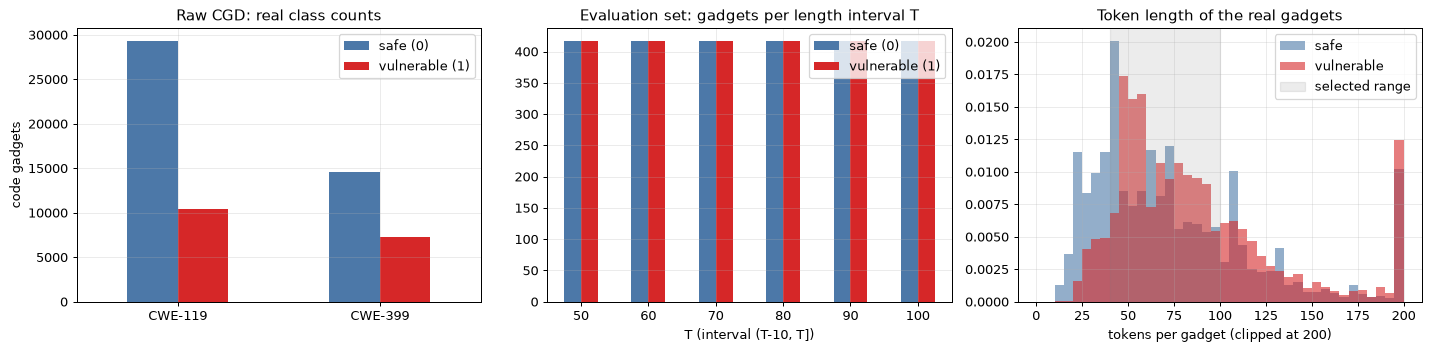

explained variance of the 2 PCA axes: 7.5% + 6.7%


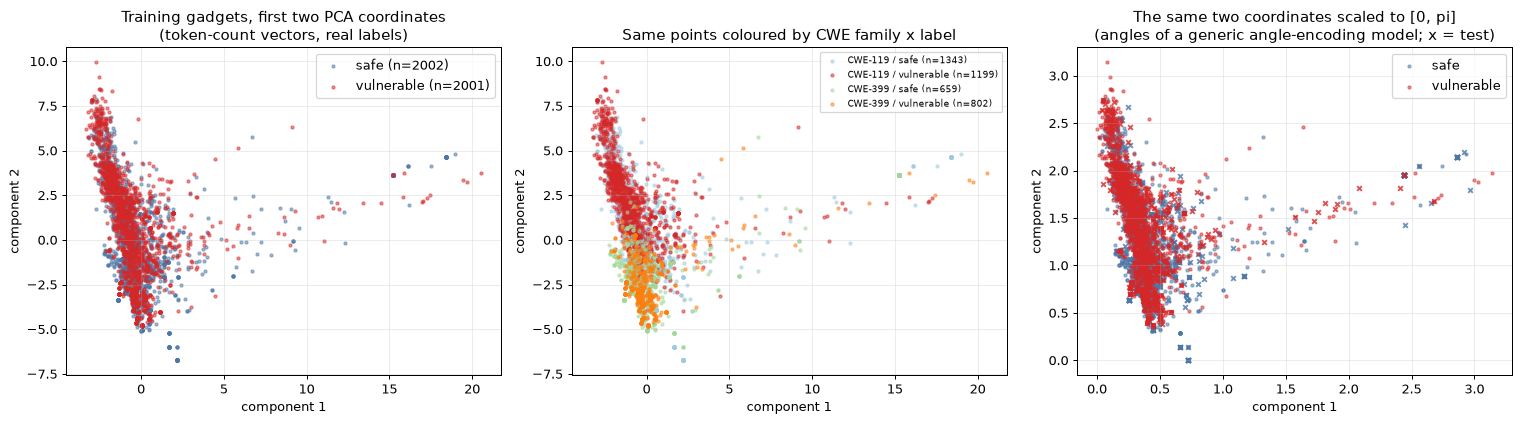

RQENN itself does not use these coordinates: it reads the token sequence through trainable Ry angles (see below).


In [7]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# ---- 1. what the raw data look like ----
print("raw dataset (VulDeePecker code gadget database, both CWE files):", raw.shape)
print("columns / 'feature names':", list(raw.columns), "+ derived: tokens, length, text")
print("original label values:", [int(v) for v in sorted(raw.label.unique())], " (0 = not vulnerable, 1 = vulnerable)")
print("CWE families:", {119: "buffer error", 399: "resource management error"})
print("\nevaluation set used here:", data.shape, "| lengths", data.length.min(), "to", data.length.max(),
      "| mean %.1f" % data.length.mean())
print(data.groupby(["cwe", "label"]).size().rename("gadgets").to_frame().T)
print("\ntwo example gadgets (normalised):")
for lab in (0, 1):
    r = data[data.label == lab].iloc[0]
    print(f"  label {lab}, CWE-{r.cwe}, {r.length} tokens: " + " ".join(r.tokens[:30]) + " ...")

fam = lambda d: d.cwe.map({119: "CWE-119", 399: "CWE-399"}) + " / " + d.label.map({0: "safe", 1: "vulnerable"})
colors4 = {"CWE-119 / safe": "#9ecae1", "CWE-119 / vulnerable": "#d62728", "CWE-399 / safe": "#a1d99b", "CWE-399 / vulnerable": "#ff7f0e"}

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
c = raw.groupby(["cwe", "label"]).size().unstack()
c.index = ["CWE-119", "CWE-399"]; c.columns = ["safe (0)", "vulnerable (1)"]
c.plot.bar(ax=ax[0], color=["#4c78a8", "#d62728"], rot=0); ax[0].set_title("Raw CGD: real class counts"); ax[0].set_ylabel("code gadgets")
ci = data.groupby(["interval", "label"]).size().unstack(); ci.columns = ["safe (0)", "vulnerable (1)"]
ci.plot.bar(ax=ax[1], color=["#4c78a8", "#d62728"], rot=0); ax[1].set_title("Evaluation set: gadgets per length interval T"); ax[1].set_xlabel("T (interval (T-10, T])")
bins = np.arange(0, 205, 5)
for lab, col, nm in [(0, "#4c78a8", "safe"), (1, "#d62728", "vulnerable")]:
    ax[2].hist(raw.length[raw.label == lab].clip(upper=200), bins=bins, alpha=0.6, color=col, label=nm, density=True)
ax[2].axvspan(INTERVALS[0][0], T_MAX, color="grey", alpha=0.15, label="selected range"); ax[2].set_xlabel("tokens per gadget (clipped at 200)")
ax[2].set_title("Token length of the real gadgets"); ax[2].legend()
plt.tight_layout(); plt.show()

# ---- 2. 2-D scatter of the real gadgets coloured by ground truth (PCA fitted on the training split of fold 0) ----
def bag(X):                                   # counts of the 128 dictionary entries (what a classical model sees)
    return np.stack([np.bincount(r, minlength=DICT_SIZE) for r in X]).astype(float)
tr0, te0 = FOLDS[0]
Ctr, Cte = bag(f0["Xtr"]), bag(f0["Xte"])
sc = StandardScaler().fit(Ctr); pca = PCA(n_components=2, random_state=SEED).fit(sc.transform(Ctr))
Ztr, Zte = pca.transform(sc.transform(Ctr)), pca.transform(sc.transform(Cte))
print("explained variance of the 2 PCA axes: %.1f%% + %.1f%%" % tuple(100 * pca.explained_variance_ratio_))
dtr, dte = data.iloc[tr0], data.iloc[te0]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for lab, col, nm in [(0, "#4c78a8", "safe"), (1, "#d62728", "vulnerable")]:
    m = f0["ytr"] == lab
    ax[0].scatter(Ztr[m, 0], Ztr[m, 1], s=6, alpha=0.5, c=col, label=f"{nm} (n={m.sum()})")
ax[0].set_title("Training gadgets, first two PCA coordinates\n(token-count vectors, real labels)"); ax[0].legend()
f4 = fam(dtr).values
for name, col in colors4.items():
    m = f4 == name; ax[1].scatter(Ztr[m, 0], Ztr[m, 1], s=6, alpha=0.5, c=col, label=f"{name} (n={m.sum()})")
ax[1].set_title("Same points coloured by CWE family x label"); ax[1].legend(fontsize=7)
mm = MinMaxScaler((0, np.pi)).fit(Ztr); A_tr = mm.transform(Ztr); A_te = np.clip(mm.transform(Zte), 0, np.pi)
for lab, col, nm in [(0, "#4c78a8", "safe"), (1, "#d62728", "vulnerable")]:
    m = f0["ytr"] == lab; ax[2].scatter(A_tr[m, 0], A_tr[m, 1], s=6, alpha=0.5, c=col, label=nm)
    m = f0["yte"] == lab; ax[2].scatter(A_te[m, 0], A_te[m, 1], s=14, marker="x", alpha=0.8, c=col)
ax[2].set_title("The same two coordinates scaled to [0, pi]\n(angles of a generic angle-encoding model; x = test)"); ax[2].legend()
for a in ax: a.set_xlabel("component 1"); a.set_ylabel("component 2")
plt.tight_layout(); plt.show()
print("RQENN itself does not use these coordinates: it reads the token sequence through trainable Ry angles (see below).")


## 2. The quantum model: an exact, differentiable RQENN

All gates of the RQENN are real (Ry, CNOT, and the Hadamard layer applied to |0...0>), so the state is a real vector of 2^7 = 128 amplitudes. For training we need gradients through up to 100 repeated cells, so the model is simulated *exactly* in PyTorch:

- the fixed part of the cell, W = U_qnn U_qe, is built as a 128 x 128 matrix from the angles (rotation layers as Kronecker products of 2 x 2 Ry matrices, CNOT layers as index permutations, the two-qubit unitaries applied on the right pair of qubits);
- the input layer U_in(x_t) is a product of seven Ry rotations whose angles are theta_0 or theta_1 according to the token's bits;
- for every token the state is updated as psi <- W U_in(x_t) psi, starting from H^7|0>; the logits are <Z_5> and <Z_6>.

This is mathematically the same circuit as the PennyLane circuit drawn in the next section; the equality is **asserted numerically** (random angles, and again with the trained model on real gadgets at full length). Qubit 0 is the most significant bit everywhere (PennyLane convention). Parameter-shift gradients on a QNode would need thousands of circuit executions per step, which is why the simulator is used for training.

In [8]:
import math
import numpy as np
import torch
import torch.nn as nn

NQ = N_QUBITS          # 7 qubits = ceil(log2(128))
DIM = 2 ** NQ
DT = torch.float64      # all gates are real (Ry, CNOT, Hadamard on |0>), so real float64 is exact

def ry_mat(a):
    """Ry(a) = [[cos a/2, -sin a/2], [sin a/2, cos a/2]] for a tensor a of any shape -> [..., 2, 2]."""
    c, s = torch.cos(a / 2), torch.sin(a / 2)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)

def kron_chain(mats):
    """Kronecker product of a list of [..., 2, 2] matrices (qubit 0 = most significant)."""
    out = mats[0]
    for M in mats[1:]:
        a = out.shape[-1]
        out = (out[..., :, None, :, None] * M[..., None, :, None, :]).reshape(*out.shape[:-2], 2 * a, 2 * a)
    return out

def cnot_matrix(c, t):
    idx = np.arange(DIM)
    new = idx ^ (((idx >> (NQ - 1 - c)) & 1) << (NQ - 1 - t))
    P = np.zeros((DIM, DIM)); P[new, idx] = 1.0          # column convention: P |i> = |new(i)>
    return torch.tensor(P, dtype=DT)

# fixed entangling layers of the QEmbedding block (Eq. 7): even pairs (0,1),(2,3),(4,5), then odd pairs (1,2),(3,4),(5,6)
P_EVEN, P_ODD = torch.eye(DIM, dtype=DT), torch.eye(DIM, dtype=DT)
for _i in range(1, NQ // 2 + 1):
    P_EVEN = cnot_matrix(2 * _i - 2, 2 * _i - 1) @ P_EVEN
for _i in range(1, (NQ - 1) // 2 + 1):
    P_ODD = cnot_matrix(2 * _i - 1, 2 * _i) @ P_ODD
CNOT4 = torch.tensor([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=DT)
SIGN = torch.tensor([[1 - 2 * ((k >> (NQ - 1 - q)) & 1) for q in (NQ - 2, NQ - 1)] for k in range(DIM)], dtype=DT)  # Z eigenvalues of qubits n-2, n-1

SRC_EVEN, SRC_ODD = P_EVEN.argmax(1), P_ODD.argmax(1)   # (P @ U)[j] = U[src[j]] for these permutation matrices

def apply_pair_gate(U, i, a, b):
    """U <- U[2] U, with U[2] of Eq. (5) on qubits (i, i+1): CNOT_{i,i+1} (Ry_i(a) x Ry_{i+1}(b)), embedded in 7 qubits."""
    u4 = CNOT4 @ torch.kron(ry_mat(a), ry_mat(b))
    X = U.reshape(2 ** i, 4, -1)
    return torch.einsum("ab,ibj->iaj", u4, X).reshape(DIM, DIM)

class RQENN(nn.Module):
    """Recurrent quantum embedding neural network (exact state-vector simulation, differentiable).

    theta_in  : 2 angles (theta_0, theta_1) that replace the bits 0/1 of the binary token index
    theta_qe  : m x 14 angles of the QEmbedding layers (two rotation layers of 7 Ry per layer)
    theta_qw  : n x 12 angles of the QWeight layers (6 two-qubit unitaries x 2 Ry per layer)
    """
    def __init__(self, m=4, n=4, encoding="parameterized", seed=0, init="uniform", theta_in0=None):
        super().__init__()
        self.m, self.n, self.encoding = m, n, encoding
        g = torch.Generator().manual_seed(seed)
        # CHOICE: the paper does not state its initialisation; `init` is either "uniform" (angles in [0, 2*pi)) or the std of a normal
        if init == "uniform":
            init_f = lambda *shape: (torch.rand(*shape, generator=g, dtype=DT) * 2 * math.pi)
        else:
            init_f = lambda *shape: (torch.randn(*shape, generator=g, dtype=DT) * float(init))
        self.theta_qe = nn.Parameter(init_f(m, 2 * NQ))
        self.theta_qw = nn.Parameter(init_f(n, 2 * (NQ - 1)))
        if encoding == "parameterized":
            self.theta_in = nn.Parameter(torch.tensor(theta_in0, dtype=DT) if theta_in0 is not None else init_f(2))
        elif encoding == "binary":
            self.register_buffer("theta_in", torch.tensor([0.0, 1.0], dtype=DT))            # theta_0 = 0, theta_1 = 1
        elif encoding == "orthogonal":
            self.register_buffer("theta_in", torch.tensor([-math.pi / 2, math.pi / 2], dtype=DT))
        else:
            raise ValueError(encoding)
        self.register_buffer("bit_shifts", torch.arange(NQ - 1, -1, -1))

    def n_parameters(self):
        return sum(p.numel() for p in self.parameters())

    def cell_unitary(self):
        """Fixed part of the cell: W = U_qnn U_qe (128 x 128, column convention)."""
        U = torch.eye(DIM, dtype=DT)
        for l in range(self.m):
            p = self.theta_qe[l]
            U = kron_chain([ry_mat(p[i]) for i in range(NQ)]) @ U            # first rotation layer, qubits 0..6
            U = U[SRC_EVEN]                                                     # CNOT(0,1) CNOT(2,3) CNOT(4,5)
            U = kron_chain([ry_mat(p[NQ + i]) for i in range(NQ)]) @ U        # second rotation layer
            U = U[SRC_ODD]                                                      # CNOT(1,2) CNOT(3,4) CNOT(5,6)
        for l in range(self.n):
            p = self.theta_qw[l]
            for i in range(NQ - 1):
                U = apply_pair_gate(U, i, p[2 * i], p[2 * i + 1])
        return U

    def forward(self, tokens):
        """tokens: LongTensor [B, T] of dictionary indices (0..127). Returns logits [B, 2] = <Z_{n-2}>, <Z_{n-1}>."""
        B, T = tokens.shape
        W = self.cell_unitary()
        # rotation layer of every one of the 128 dictionary entries (computed once, then looked up per token)
        bits = (torch.arange(DIM)[:, None] >> self.bit_shifts) & 1           # [128, 7] binary index, qubit i <- bit i
        R = ry_mat(self.theta_in[bits])                                       # [128, 7, 2, 2]  Ry(theta_bit)
        A_all = kron_chain([R[:, q] for q in range(3)])                      # [128, 8, 8]   qubits 0-2
        C_all = kron_chain([R[:, q] for q in range(3, NQ)])                  # [128, 16, 16] qubits 3-6
        A, C = A_all[tokens], C_all[tokens]                                  # [B, T, 8, 8], [B, T, 16, 16]
        psi = torch.full((B, DIM), 1.0 / math.sqrt(DIM), dtype=DT)            # H^{(x)7}|0>
        WT = W.T
        for A_t, CT_t in zip(A.unbind(1), C.transpose(-1, -2).unbind(1)):
            psi = (A_t @ psi.reshape(B, 8, 16) @ CT_t).reshape(B, DIM)        # U_in(x_t)
            psi = psi @ WT                                                    # U_qnn U_qe
        return (psi ** 2) @ SIGN


## Quantum Circuit Architecture

The circuits below are drawn from the **real PennyLane QNode** `rqenn_circuit`, which is the executed reference of the model (the simulator used for training is asserted equal to it). They show the Hadamard layer that creates the initial hidden state, the rotation input layer (the angle on qubit i is theta_0 or theta_1 depending on bit i of the token index), the QEmbedding layers (two Ry layers and two staggered CNOT layers each), the QWeight layers (a chain of two-qubit unitaries Ry-Ry-CNOT), and the two Pauli-Z measurements on qubits 5 and 6. A full gadget repeats this cell once per token with shared parameters. Assumptions where the paper is silent: the order of the two Ry layers and the CNOT layers inside QEmbedding follows Eq. (7) read right-to-left; QWeight layers all use the 6-unitary chain of Eq. (9) (n layers = n chains); the first Ry layer of QEmbedding acts directly after the input rotations.

In [9]:
import pennylane as qml
import matplotlib.pyplot as plt

dev = qml.device("default.qubit", wires=NQ)

def rqenn_circuit(tokens, th_in, th_qe, th_qw):
    """The RQENN circuit of the paper, gate by gate (Fig. 2 and 3, Eqs. 4-11): H^7, then the same cell for every token, then <Z_5>, <Z_6>."""
    for q in range(NQ):
        qml.Hadamard(wires=q)                                              # hidden state at t = 0
    for tok in tokens:
        for q in range(NQ):                                                # rotation input layer U_in(x_t): bit i -> Ry(theta_bit) on qubit i
            qml.RY(th_in[(tok >> (NQ - 1 - q)) & 1], wires=q)
        for l in range(th_qe.shape[0]):                                    # QEmbedding layer l (Eq. 7)
            for i in range(NQ): qml.RY(th_qe[l, i], wires=i)
            for i in range(1, NQ // 2 + 1): qml.CNOT(wires=[2 * i - 2, 2 * i - 1])
            for i in range(NQ): qml.RY(th_qe[l, NQ + i], wires=i)
            for i in range(1, (NQ - 1) // 2 + 1): qml.CNOT(wires=[2 * i - 1, 2 * i])
        for l in range(th_qw.shape[0]):                                    # QWeight layer l (Eqs. 5 and 9): chain of two-qubit unitaries
            for i in range(NQ - 1):
                qml.RY(th_qw[l, 2 * i], wires=i); qml.RY(th_qw[l, 2 * i + 1], wires=i + 1)
                qml.CNOT(wires=[i, i + 1])
    return [qml.expval(qml.PauliZ(NQ - 2)), qml.expval(qml.PauliZ(NQ - 1))]   # Eqs. 10-11

rqenn_qnode = qml.QNode(rqenn_circuit, dev)

def pl_logits(model, token_seq):
    """Run the real PennyLane QNode with the parameters of a torch RQENN model."""
    out = rqenn_qnode(list(map(int, token_seq)), model.theta_in.detach().numpy(), model.theta_qe.detach().numpy(), model.theta_qw.detach().numpy())
    return np.array([float(o) for o in out])

def circuit_resources(model, token_seq):
    tape = qml.workflow.construct_tape(rqenn_qnode)(list(map(int, token_seq)), model.theta_in.detach().numpy(),
                                                    model.theta_qe.detach().numpy(), model.theta_qw.detach().numpy())
    gates = collections.Counter(op.name for op in tape.operations)
    return {"qubits": NQ, "gates": len(tape.operations), "depth": tape.graph.get_depth(), "by gate": dict(gates)}


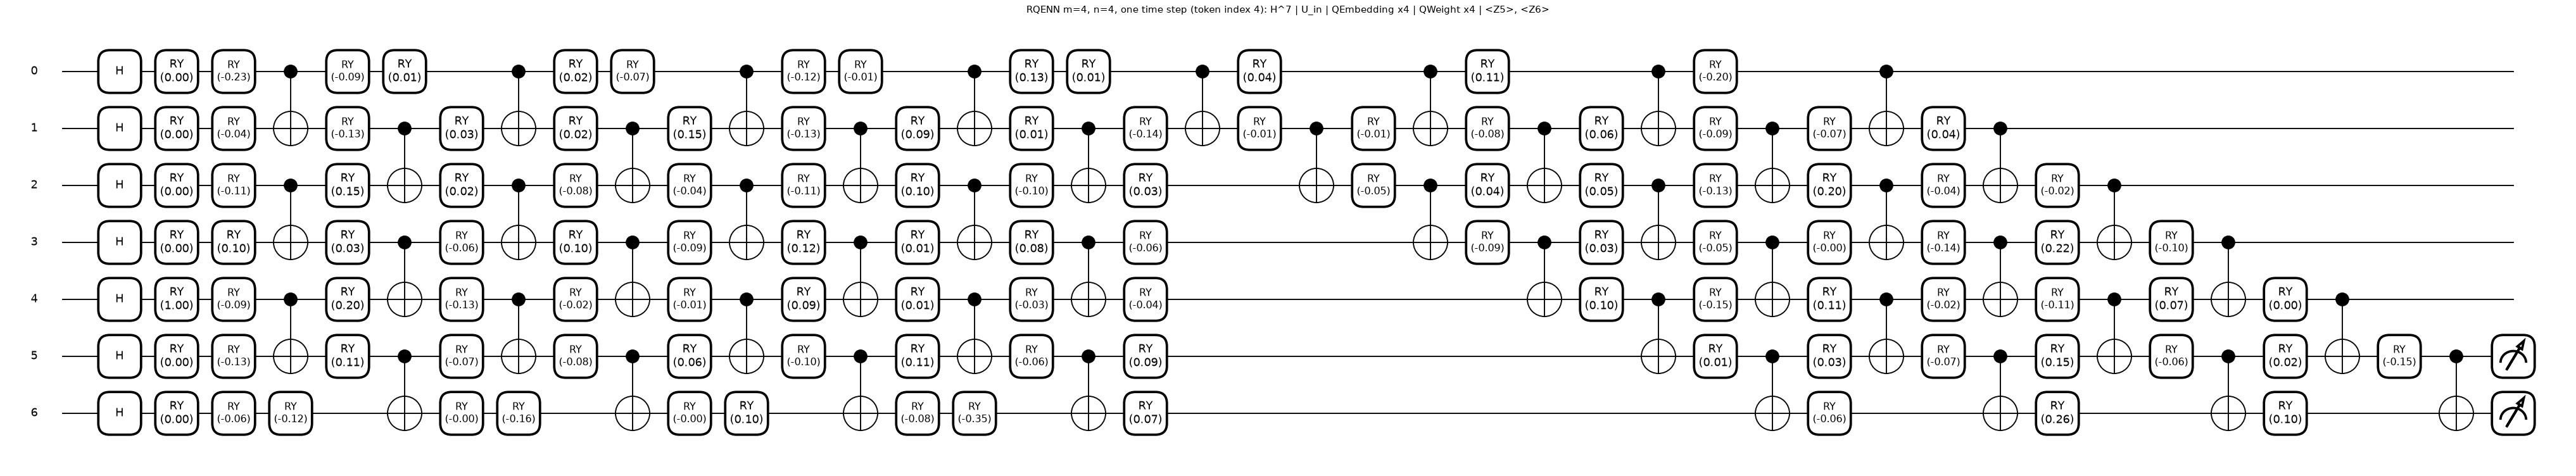

RQENN m=4, n=4, one time step (token index 4): H^7 | U_in | QEmbedding x4 | QWeight x4 | <Z5>, <Z6>
  qubits = 7, gates = 166 {'Hadamard': 7, 'RY': 111, 'CNOT': 48}, depth = 42, trainable parameters of the model = 106


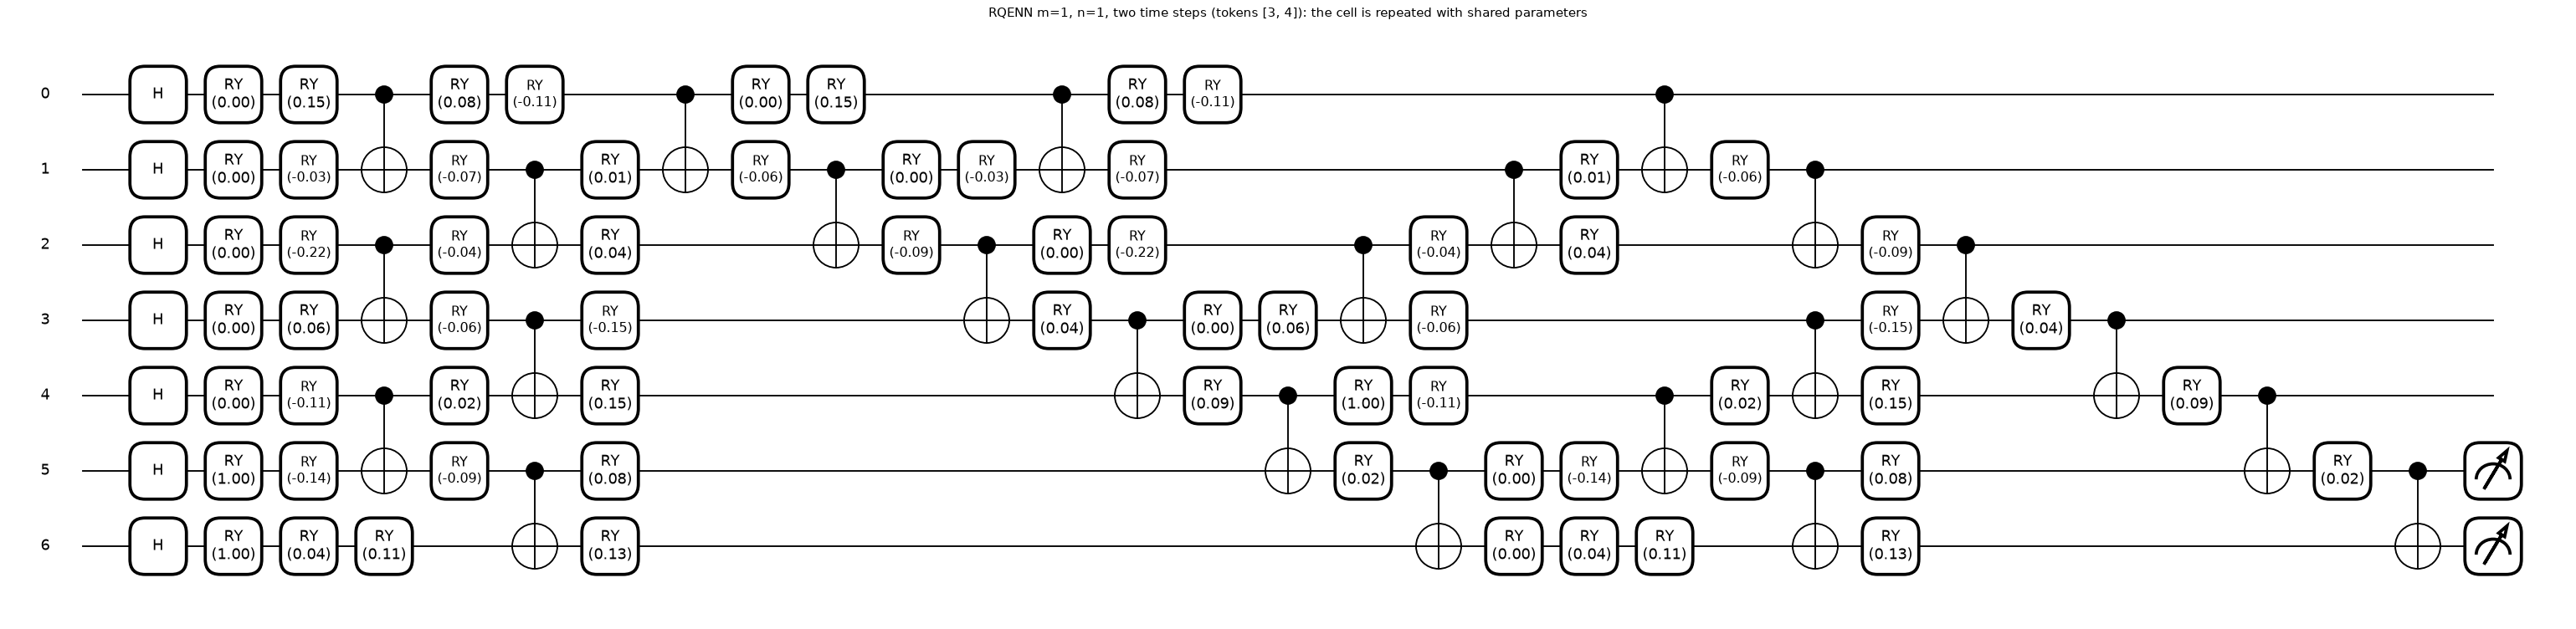

RQENN m=1, n=1, two time steps (tokens [3, 4]): the cell is repeated with shared parameters
  qubits = 7, gates = 97 {'Hadamard': 7, 'RY': 66, 'CNOT': 24}, depth = 31, trainable parameters of the model = 28


,m (QEmbedding),n (QWeight),qubits,"gates, 1 cell","depth, 1 cell","depth, T=100 steps (approx.)",trainable parameters
0,1,1,7,45,17,1701,28
1,2,2,7,83,25,2501,54
2,4,4,7,159,41,4101,106


Paper: 7 qubits and 106 parameters for m = n = 4; here 106 parameters.


Simulator == PennyLane QNode for 3 architectures x 3 random 5-token sequences: max |difference| = 1.4e-15  -> assertion passed


In [10]:
def make_rqenn(m=M_LAYERS, n=N_LAYERS, enc="parameterized", seed=0):
    return RQENN(m, n, enc, seed=seed, init=INIT_STD, theta_in0=list(THETA_IN_INIT))

def draw(model, tokens, title):
    args = (list(map(int, tokens)), model.theta_in.detach().numpy(), model.theta_qe.detach().numpy(), model.theta_qw.detach().numpy())
    fig, ax = qml.draw_mpl(rqenn_qnode, decimals=2, wire_order=list(range(NQ)))(*args)
    fig.suptitle(title, y=1.02); plt.show()
    res = circuit_resources(model, tokens)
    print(f"{title}\n  qubits = {res['qubits']}, gates = {res['gates']} {res['by gate']}, depth = {res['depth']}, "
          f"trainable parameters of the model = {model.n_parameters()}")

# (a) the architecture the paper selects (m = 4 QEmbedding layers, n = 4 QWeight layers): ONE time step of the real QNode
tok_demo = [int(f0["Xte"][0][-1])]
m44 = make_rqenn(4, 4)
draw(m44, tok_demo, f"RQENN m=4, n=4, one time step (token index {tok_demo[0]}): H^7 | U_in | QEmbedding x4 | QWeight x4 | <Z5>, <Z6>")

# (b) the smallest architecture, TWO time steps, to make the recurrence visible (the same cell, the same angles, a different token)
tok2 = [int(t) for t in f0["Xte"][0][-2:]]
draw(make_rqenn(1, 1), tok2, f"RQENN m=1, n=1, two time steps (tokens {tok2}): the cell is repeated with shared parameters")

# (c) resource table: one distinct architecture per (m, n) used in this notebook; a full sequence repeats the cell T times
rows = []
for (m, n) in sorted(set([(M_LAYERS, N_LAYERS)] + list(GRID))):
    mod = make_rqenn(m, n); r1 = circuit_resources(mod, tok_demo[:1])
    rows.append({"m (QEmbedding)": m, "n (QWeight)": n, "qubits": NQ, "gates, 1 cell": r1["gates"] - NQ, "depth, 1 cell": r1["depth"] - 1,
                 f"depth, T={T_MAX} steps (approx.)": (r1["depth"] - 1) * T_MAX + 1, "trainable parameters": mod.n_parameters()})
display(pd.DataFrame(rows))
print("Paper: 7 qubits and 106 parameters for m = n = 4; here", make_rqenn(4, 4).n_parameters(), "parameters.")

# (d) the exact differentiable simulator used for training must agree with the real PennyLane QNode
chk = np.random.default_rng(SEED)
worst = 0.0
for m, n, enc in [(4, 4, "parameterized"), (2, 3, "orthogonal"), (1, 1, "binary")]:
    mod = make_rqenn(m, n, enc, seed=int(chk.integers(1000)))
    with torch.no_grad():                                   # random (non-small) angles so the check is not trivial
        for p in mod.parameters(): p.copy_(torch.as_tensor(chk.uniform(0, 2 * np.pi, p.shape)))
    seq = chk.integers(0, DICT_SIZE, size=(3, 5))
    with torch.no_grad(): sim = mod(torch.as_tensor(seq)).numpy()
    ref = np.stack([pl_logits(mod, s) for s in seq])
    worst = max(worst, np.abs(sim - ref).max())
    assert np.allclose(sim, ref, atol=1e-9), (m, n, enc, np.abs(sim - ref).max())
print(f"Simulator == PennyLane QNode for 3 architectures x 3 random 5-token sequences: max |difference| = {worst:.1e}  -> assertion passed")


## 3. Training the RQENN and the classical models

Training follows the paper: Adam, learning rate 0.01, batch size 64, cross-entropy on the two outputs, test accuracy after every epoch, k-fold cross-validation. The classical RNN has the paper's sizes (embedding 128, hidden 128, 49,666 parameters); an LSTM of the same width and two non-sequential baselines (Random Forest and an RBF-SVC on the counts of the 128 dictionary entries) use the same dictionary, folds and data. The paper reports the *best* test accuracy over the epochs; because that selects on the test fold we also print the final-epoch accuracy. Confusion matrices treat *vulnerable* as the positive class.

RandomForest accuracy per fold: [0.949 0.93  0.95  0.935 0.933] | SVC rbf: [0.883 0.855 0.858 0.864 0.884]
training RQENN, RNN and LSTM:


  RQENN (m=4, n=4)       fold 0: best-epoch acc 0.591 | final-epoch acc 0.542 | loss 0.699 -> 0.686 | 212 s


  RQENN (m=4, n=4)       fold 1: best-epoch acc 0.598 | final-epoch acc 0.590 | loss 0.682 -> 0.663 | 158 s


  RQENN (m=4, n=4)       fold 2: best-epoch acc 0.610 | final-epoch acc 0.610 | loss 0.683 -> 0.671 | 219 s


  RQENN (m=4, n=4)       fold 3: best-epoch acc 0.612 | final-epoch acc 0.587 | loss 0.687 -> 0.683 | 193 s


...

  classical LSTM         fold 1: best-epoch acc 0.777 | final-epoch acc 0.769 | loss 0.754 -> 0.396 | 112 s


  classical LSTM         fold 2: best-epoch acc 0.802 | final-epoch acc 0.798 | loss 0.824 -> 0.280 | 90 s


  classical LSTM         fold 3: best-epoch acc 0.801 | final-epoch acc 0.801 | loss 0.722 -> 0.387 | 82 s


  classical LSTM         fold 4: best-epoch acc 0.844 | final-epoch acc 0.844 | loss 0.759 -> 0.369 | 82 s


,"best-epoch acc, median","best-epoch acc, mean","final-epoch acc, mean","final-epoch acc, std",seconds / fold
RandomForest (counts),0.935,0.939,0.939,0.008,3.2
SVC rbf (counts),0.864,0.869,0.869,0.012,2.7
RQENN,0.610,0.605,0.584,0.022,182.3
RNN,0.673,0.677,0.651,0.036,46.0
LSTM,0.802,0.817,0.814,0.033,93.7


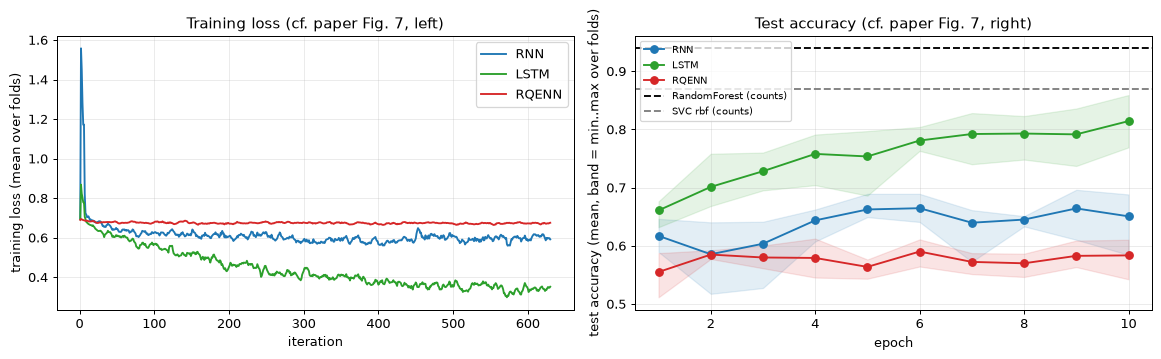

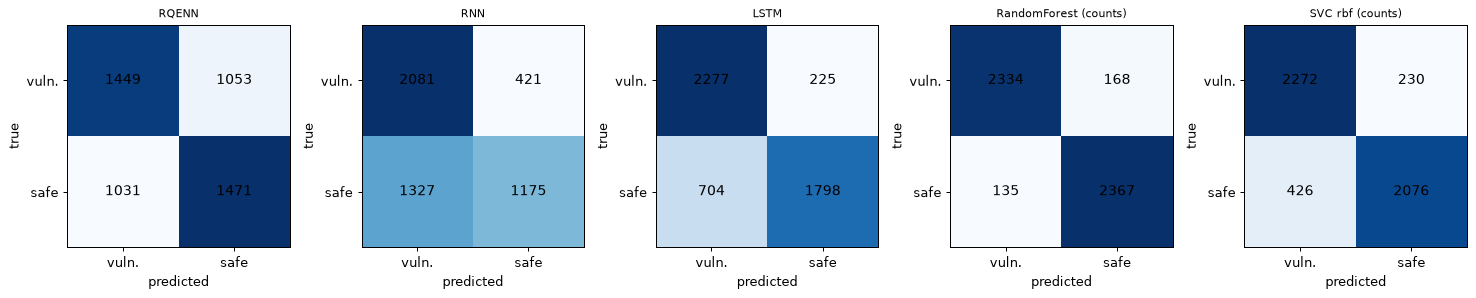

,accuracy,precision,recall,f1
model,,,,
RQENN,0.584 +- 0.022,0.585 +- 0.025,0.579 +- 0.019,0.582 +- 0.015
RNN,0.651 +- 0.036,0.613 +- 0.031,0.832 +- 0.083,0.703 +- 0.034
LSTM,0.814 +- 0.033,0.768 +- 0.052,0.910 +- 0.021,0.832 +- 0.023
RandomForest (counts),0.939 +- 0.008,0.945 +- 0.011,0.933 +- 0.015,0.939 +- 0.009
SVC rbf (counts),0.869 +- 0.012,0.843 +- 0.018,0.908 +- 0.017,0.874 +- 0.011


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

RES = {}          # name -> list of per-fold result dicts
def run_cv(name, make_model, fold_ids, epochs=EPOCHS, store_model=False):
    out = []
    for k in fold_ids:
        d = FOLD_DATA[k]
        model = make_model(SEED + k)
        r = train_eval(model, d["Xtr"], d["ytr"], d["Xte"], d["yte"], epochs, seed=SEED + k)
        r["fold"], r["yte"] = k, d["yte"]
        if store_model: r["model"] = model
        out.append(r)
        print(f"  {name:<22} fold {k}: best-epoch acc {r['best_acc']:.3f} | final-epoch acc {r['final_acc']:.3f} | "
              f"loss {np.mean(r['losses'][:5]):.3f} -> {np.mean(r['losses'][-5:]):.3f} | {r['seconds']:.0f} s", flush=True)
    return out

# ---- classical non-sequential baselines on the SAME dictionary (counts of the 128 dictionary entries) ----
rf_res, svc_res = [], []
for k, d in enumerate(FOLD_DATA):
    Ctr, Cte = bag(d["Xtr"]), bag(d["Xte"])
    t0 = time.perf_counter(); rf = RandomForestClassifier(300, random_state=SEED, n_jobs=1).fit(Ctr, d["ytr"]); p = rf.predict(Cte)
    rf_res.append({"fold": k, "pred": p, "yte": d["yte"], "final_acc": accuracy_score(d["yte"], p), "best_acc": accuracy_score(d["yte"], p), "seconds": time.perf_counter() - t0})
    s = StandardScaler().fit(Ctr); t0 = time.perf_counter(); sv = SVC(kernel="rbf", C=1.0, random_state=SEED).fit(s.transform(Ctr), d["ytr"]); p = sv.predict(s.transform(Cte))
    svc_res.append({"fold": k, "pred": p, "yte": d["yte"], "final_acc": accuracy_score(d["yte"], p), "best_acc": accuracy_score(d["yte"], p), "seconds": time.perf_counter() - t0})
RES["RandomForest (counts)"], RES["SVC rbf (counts)"] = rf_res, svc_res
print("RandomForest accuracy per fold:", np.round([r["final_acc"] for r in rf_res], 3), "| SVC rbf:", np.round([r["final_acc"] for r in svc_res], 3))

# ---- the paper's three sequence models on identical token sequences, identical folds, identical optimiser settings ----
print("training RQENN, RNN and LSTM:")
RES["RQENN"] = run_cv("RQENN (m=4, n=4)", lambda s: make_rqenn(M_LAYERS, N_LAYERS, "parameterized", s), range(N_FOLDS), store_model=True)
RES["RNN"] = run_cv("classical RNN", lambda s: ClassicalRNN("rnn", s), range(N_FOLDS))
RES["LSTM"] = run_cv("classical LSTM", lambda s: ClassicalRNN("lstm", s), range(N_FOLDS))

def summarise(res):
    best, fin = np.array([r["best_acc"] for r in res]), np.array([r["final_acc"] for r in res])
    return {"best-epoch acc, median": np.median(best), "best-epoch acc, mean": best.mean(), "final-epoch acc, mean": fin.mean(),
            "final-epoch acc, std": fin.std(), "seconds / fold": np.mean([r["seconds"] for r in res])}
SUM = pd.DataFrame({k: summarise(v) for k, v in RES.items()}).T
display(SUM.style.format({c: "{:.3f}" for c in SUM.columns[:4]} | {"seconds / fold": "{:.1f}"}))

# ---- the paper's Fig. 7 (loss and test accuracy during training) ----
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, col in [("RNN", "tab:blue"), ("LSTM", "tab:green"), ("RQENN", "tab:red")]:
    L = np.mean([r["losses"] for r in RES[name]], axis=0)
    ax[0].plot(np.arange(1, len(L) + 1), pd.Series(L).rolling(5, min_periods=1).mean(), color=col, label=name)
    A = np.array([r["test_acc"] for r in RES[name]])
    ax[1].plot(np.arange(1, A.shape[1] + 1), A.mean(0), "-o", color=col, label=name); ax[1].fill_between(np.arange(1, A.shape[1] + 1), A.min(0), A.max(0), color=col, alpha=0.12)
for nm, col in [("RandomForest (counts)", "k"), ("SVC rbf (counts)", "grey")]:
    ax[1].axhline(np.mean([r["final_acc"] for r in RES[nm]]), ls="--", color=col, label=nm)
ax[0].set(xlabel="iteration", ylabel="training loss (mean over folds)", title="Training loss (cf. paper Fig. 7, left)")
ax[1].set(xlabel="epoch", ylabel="test accuracy (mean, band = min..max over folds)", title="Test accuracy (cf. paper Fig. 7, right)")
ax[0].legend(); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

# ---- confusion matrices (vulnerable = positive class) and precision / recall / F1, final epoch, all folds pooled ----
def pooled(res): return np.concatenate([r["yte"] for r in res]), np.concatenate([r["pred"] for r in res])
names = ["RQENN", "RNN", "LSTM", "RandomForest (counts)", "SVC rbf (counts)"]
fig, ax = plt.subplots(1, len(names), figsize=(3.3 * len(names), 3.3))
rows = []
for a, nm in zip(ax, names):
    y, p = pooled(RES[nm]); cm = confusion_matrix(y, p, labels=[1, 0])
    a.imshow(cm, cmap="Blues"); a.set_xticks([0, 1], ["vuln.", "safe"]); a.set_yticks([0, 1], ["vuln.", "safe"]); a.grid(False)
    for i in range(2):
        for j in range(2): a.text(j, i, cm[i, j], ha="center", va="center", color="black", fontsize=11)
    a.set_title(nm, fontsize=9); a.set_xlabel("predicted"); a.set_ylabel("true")
    per_fold = [metrics(r["yte"], r["pred"]) for r in RES[nm]]
    rows.append({"model": nm, **{k: f"{np.mean([m[k] for m in per_fold]):.3f} +- {np.std([m[k] for m in per_fold]):.3f}" for k in per_fold[0]}})
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index("model"))


### Does the trained circuit still equal the simulator? (full-length gadgets, real QNode)

The trained fold-0 RQENN is evaluated on real test gadgets at full length through the PennyLane circuit (a few hundred gates per time step, so only two gadgets to keep the runtime small).

In [12]:
# The model trained above (fold 0) is run on real test gadgets, full length, through the real PennyLane QNode.
m0 = RES["RQENN"][0]["model"]
N_CHECK = 2
Xcheck = FOLD_DATA[0]["Xte"][:N_CHECK]
with torch.no_grad(): sim = m0(torch.as_tensor(Xcheck)).numpy()
t0 = time.perf_counter()
ref = np.stack([pl_logits(m0, s) for s in Xcheck])
print(f"PennyLane default.qubit, {N_CHECK} gadgets x {Xcheck.shape[1]} time steps ({time.perf_counter() - t0:.0f} s):")
print("  simulator logits :", np.round(sim, 6).tolist())
print("  QNode logits     :", np.round(ref, 6).tolist())
assert np.allclose(sim, ref, atol=1e-9), np.abs(sim - ref).max()
print(f"  max |difference| = {np.abs(sim - ref).max():.1e}  -> trained model and real circuit agree; predictions identical:",
      bool((sim.argmax(1) == ref.argmax(1)).all()))
print("learned angles of the input layer: theta_0 = %.3f, theta_1 = %.3f  (started at %s)" % (*m0.theta_in.detach().numpy(), THETA_IN_INIT))


PennyLane default.qubit, 2 gadgets x 100 time steps (3 s):
  simulator logits : [[0.027109, 0.02769], [0.008224, -0.166269]]
  QNode logits     : [[0.027109, 0.02769], [0.008224, -0.166269]]
  max |difference| = 4.7e-15  -> trained model and real circuit agree; predictions identical: True
learned angles of the input layer: theta_0 = -0.008, theta_1 = 0.694  (started at (0.0, 1.0))


## 4. Ablations: encoding, number of layers, code length

Paper Fig. 6: parameterised binary index (trainable theta_0, theta_1) vs the *orthogonal* fixed angles (-pi/2, pi/2) vs the plain *binary* index (theta = 0, 1). Paper Fig. 5: a grid over m QEmbedding and n QWeight layers. Paper Fig. 8 / Table 3: each length interval trained on its own with T equal to the interval's upper end. In `FAST_MODE` the ablations use one fold and a small grid; the full 5-fold, 6 x 6 budgets are in the configuration cell.

encoding ablation on folds [0] (same folds as the main run):


  RQENN, binary index    fold 0: best-epoch acc 0.613 | final-epoch acc 0.553 | loss 0.695 -> 0.681 | 78 s


  RQENN, orthogonal      fold 0: best-epoch acc 0.635 | final-epoch acc 0.600 | loss 0.692 -> 0.665 | 77 s


,"best-epoch acc, median","final-epoch acc, mean",trainable parameters
parameterized binary index,0.591,0.542,106
"binary index (theta = 0, 1)",0.613,0.553,104
"orthogonal (theta = -pi/2, pi/2)",0.635,0.600,104


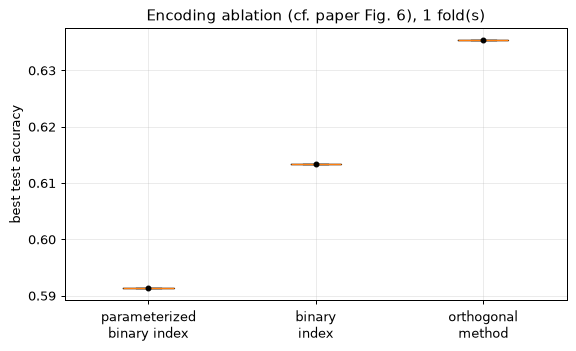

layer grid [(1, 1), (2, 2), (4, 4)] on folds [0]:


  RQENN m=1, n=1         fold 0: best-epoch acc 0.611 | final-epoch acc 0.611 | loss 0.684 -> 0.684 | 63 s


  RQENN m=2, n=2         fold 0: best-epoch acc 0.601 | final-epoch acc 0.595 | loss 0.693 -> 0.675 | 71 s


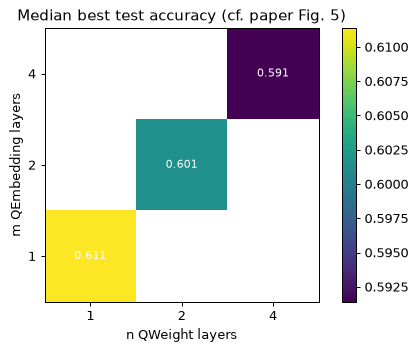

  T=50  RQENN  best test acc per fold [0.85]


  T=50  RNN    best test acc per fold [0.844]


  T=60  RQENN  best test acc per fold [0.82]


  T=60  RNN    best test acc per fold [0.689]


  T=70  RQENN  best test acc per fold [0.695]


...

  T=90  RQENN  best test acc per fold [0.653]


  T=90  RNN    best test acc per fold [0.683]


  T=100 RQENN  best test acc per fold [0.677]


  T=100 RNN    best test acc per fold [0.659]


,RQENN,RNN
T,,
50,0.850,0.844
60,0.820,0.689
70,0.695,0.713
80,0.719,0.766
90,0.653,0.683
100,0.677,0.659


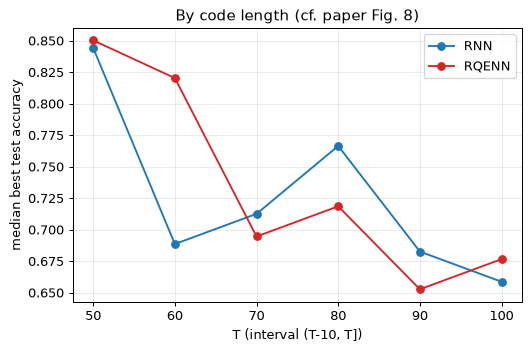

In [13]:
abl_ids = list(range(ABL_FOLDS))
print(f"encoding ablation on folds {abl_ids} (same folds as the main run):")
ABL = {"parameterized binary index": RES["RQENN"][:ABL_FOLDS]}
ABL["binary index (theta = 0, 1)"] = run_cv("RQENN, binary index", lambda s: make_rqenn(M_LAYERS, N_LAYERS, "binary", s), abl_ids)
ABL["orthogonal (theta = -pi/2, pi/2)"] = run_cv("RQENN, orthogonal", lambda s: make_rqenn(M_LAYERS, N_LAYERS, "orthogonal", s), abl_ids)
abl_tab = pd.DataFrame({k: {"best-epoch acc, median": np.median([r["best_acc"] for r in v]), "final-epoch acc, mean": np.mean([r["final_acc"] for r in v]),
                            "trainable parameters": 106 if "parameterized" in k else 104} for k, v in ABL.items()}).T
display(abl_tab.style.format({"best-epoch acc, median": "{:.3f}", "final-epoch acc, mean": "{:.3f}", "trainable parameters": "{:.0f}"}))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.boxplot([[r["best_acc"] for r in v] for v in ABL.values()]); ax.set_xticks([1, 2, 3], ["parameterized\nbinary index", "binary\nindex", "orthogonal\nmethod"])
for i, v in enumerate(ABL.values(), 1): ax.scatter([i] * len(v), [r["best_acc"] for r in v], color="k", s=14, zorder=3)
ax.set_ylabel("best test accuracy"); ax.set_title(f"Encoding ablation (cf. paper Fig. 6), {ABL_FOLDS} fold(s)"); plt.tight_layout(); plt.show()

# ---- layer grid (paper Fig. 5): m QEmbedding x n QWeight layers ----
grid_cfgs = sorted(set(GRID) | {(M_LAYERS, N_LAYERS)})
print(f"layer grid {grid_cfgs} on folds {abl_ids}:")
GRIDRES = {(M_LAYERS, N_LAYERS): RES["RQENN"][:ABL_FOLDS]}
for (m, n) in grid_cfgs:
    if (m, n) not in GRIDRES:
        GRIDRES[(m, n)] = run_cv(f"RQENN m={m}, n={n}", lambda s, m=m, n=n: make_rqenn(m, n, "parameterized", s), abl_ids)
mat = pd.DataFrame({(m, n): [np.median([r["best_acc"] for r in v])] for (m, n), v in GRIDRES.items()}).T.reset_index()
mat.columns = ["m", "n", "acc"]; heat = mat.pivot(index="m", columns="n", values="acc").sort_index()
fig, ax = plt.subplots(figsize=(1.2 * max(3, heat.shape[1]) + 2, 1.0 * max(3, heat.shape[0]) + 1))
im = ax.imshow(heat.values, cmap="viridis", origin="lower"); ax.grid(False)
ax.set_xticks(range(heat.shape[1]), heat.columns); ax.set_yticks(range(heat.shape[0]), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        if not np.isnan(heat.values[i, j]): ax.text(j, i, f"{heat.values[i, j]:.3f}", ha="center", va="center", color="w", fontsize=9)
ax.set_xlabel("n QWeight layers"); ax.set_ylabel("m QEmbedding layers"); ax.set_title("Median best test accuracy (cf. paper Fig. 5)")
plt.colorbar(im); plt.tight_layout(); plt.show()

# ---- length-interval study (paper Fig. 8 / Table 3): each interval alone, T = upper end of the interval ----
IV = {}
for lo, hi in INTERVALS:
    sub = data[data.interval == hi].reset_index(drop=True)
    sub_folds = folds_for(sub, max(N_FOLDS, 3))[:IV_FOLDS]
    for model_name, mk in [("RQENN", lambda s: make_rqenn(M_LAYERS, N_LAYERS, "parameterized", s)), ("RNN", lambda s: ClassicalRNN("rnn", s))]:
        accs = []
        for k, (tr, te) in enumerate(sub_folds):
            vocab = build_vocab(sub.tokens.iloc[tr])
            Xtr, Xte = encode(sub.tokens.iloc[tr], vocab, hi), encode(sub.tokens.iloc[te], vocab, hi)
            r = train_eval(mk(SEED + k), Xtr, sub.label.values[tr], Xte, sub.label.values[te], EPOCHS, seed=SEED + k)
            accs.append(r["best_acc"])
        IV[(hi, model_name)] = accs
        print(f"  T={hi:<3} {model_name:<6} best test acc per fold {np.round(accs, 3)}", flush=True)
iv = pd.DataFrame({m: {hi: np.median(IV[(hi, m)]) for _, hi in INTERVALS} for m in ["RQENN", "RNN"]})
iv.index.name = "T"; display(iv.style.format("{:.3f}"))
fig, ax = plt.subplots(figsize=(6, 4))
for m, col in [("RNN", "tab:blue"), ("RQENN", "tab:red")]: ax.plot(iv.index, iv[m], "-o", color=col, label=m)
ax.set(xlabel="T (interval (T-10, T])", ylabel="median best test accuracy", title="By code length (cf. paper Fig. 8)"); ax.legend(); plt.tight_layout(); plt.show()


## 5. Memory and parameter counts (paper Tables 1 and 2)

Table 1 of the paper is a statement about space complexity (RNN: O(N), O(N x T), O(d), O(h) versus RQENN: O(log2 N), O(log2 N x T), O(log2 d), O(log2 h)); it is an analytic argument, not an experiment. Table 2 counts parameters, which we can verify exactly.

In [14]:
rnn_m, q_m = ClassicalRNN("rnn"), make_rqenn(4, 4)
count = lambda mod: sum(p.numel() for p in mod.parameters())
t2 = pd.DataFrame({
    "RNN (paper)": [0, 16384, 33024, 258, 49666], "RNN (counted here)": [0, count(rnn_m.emb), count(rnn_m.rec), count(rnn_m.out), rnn_m.n_parameters()],
    "RQENN (paper)": [2, 56, 48, 0, 106],
    "RQENN (counted here)": [q_m.theta_in.numel(), q_m.theta_qe[:, :].numel(), q_m.theta_qw.numel(), 0, q_m.n_parameters()]},
    index=["input layer", "word embedding layer", "recurrent cell", "output layer", "total"])
display(t2)
assert (t2["RNN (paper)"] == t2["RNN (counted here)"]).all() and (t2["RQENN (paper)"] == t2["RQENN (counted here)"]).all()
print("Table 2 of the paper is reproduced exactly (counted from the models that are trained in this notebook).")
print("parameter ratio RQENN / RNN = %.4f %%  (paper: 0.21 %%)" % (100 * q_m.n_parameters() / rnn_m.n_parameters()))
print("classical bits of the RNN at float32: 49,666 x 32 = %s (the paper prints 1,585,216, which equals 49,538 x 32: an arithmetic slip of 128 parameters)" % format(49666 * 32, ","))
print("RQENN inference qubits:", NQ, "| dictionary of 128 entries stored as ceil(log2 128) = 7 qubit indices")
print("\nSpace needed for the simulated state itself on this CPU: 2^7 amplitudes = %d float64 numbers; the classical simulation therefore does NOT save memory, "
      "it only shows what a quantum computer would hold in 7 qubits." % DIM)


,RNN (paper),RNN (counted here),RQENN (paper),RQENN (counted here)
input layer,0,0,2,2
word embedding layer,16384,16384,56,56
recurrent cell,33024,33024,48,48
output layer,258,258,0,0
total,49666,49666,106,106


Table 2 of the paper is reproduced exactly (counted from the models that are trained in this notebook).
parameter ratio RQENN / RNN = 0.2134 %  (paper: 0.21 %)
classical bits of the RNN at float32: 49,666 x 32 = 1,589,312 (the paper prints 1,585,216, which equals 49,538 x 32: an arithmetic slip of 128 parameters)
RQENN inference qubits: 7 | dictionary of 128 entries stored as ceil(log2 128) = 7 qubit indices

Space needed for the simulated state itself on this CPU: 2^7 amplitudes = 128 float64 numbers; the classical simulation therefore does NOT save memory, it only shows what a quantum computer would hold in 7 qubits.


## 6. Side-by-side with the paper

Tolerance as in the project rules: a claim is *reproduced* if it is within 2 accuracy points; otherwise *not reached* or *exceeded* with the gap; claims that need data or models this notebook does not have are *cannot be checked*. Remember that `FAST_MODE` covers only lengths (40, 60].

In [15]:
TOL = 0.02          # brief: "reproduced" when within 2 accuracy points
def verdict(paper, mine, tol=TOL):
    if mine is None or (isinstance(mine, float) and np.isnan(mine)): return "cannot be checked"
    d = mine - paper
    return "reproduced" if abs(d) <= tol else ("exceeded (%+.1f pts)" % (100 * d) if d > 0 else "not reached (%+.1f pts)" % (100 * d))
pc = lambda x: "-" if x is None else f"{100 * x:.1f}%"
FULL_RANGE = (T_MAX == 100)
why_range = "cannot be checked: FAST_MODE covers lengths (40, %d] only, the paper's value is for (40, 100]" % T_MAX
best_med = lambda res: float(np.median([r["best_acc"] for r in res]))
best_mean = lambda res: float(np.mean([r["best_acc"] for r in res]))
rq, rn, ls = best_med(RES["RQENN"]), best_med(RES["RNN"]), best_med(RES["LSTM"])
rows = []
def add(claim, paper, mine, ver): rows.append({"claim": claim, "paper": paper, "this notebook": mine, "verdict": ver})

add("RQENN (m=n=4) has 106 trainable parameters", "106", str(q_m.n_parameters()), "reproduced" if q_m.n_parameters() == 106 else "not reached")
add("classical RNN has 49,666 parameters; RQENN uses 0.21 %", "49,666 / 0.21 %", f"{rnn_m.n_parameters():,} / {100 * 106 / rnn_m.n_parameters():.2f} %", "reproduced")
add("RQENN needs 7 qubits (dictionary 128)", "7 qubits", f"{NQ} qubits", "reproduced")
add("RQENN best test accuracy, full length range, m=n=4 (Fig. 5, Fig. 7)", "87.4% (median) / 85.4% (mean)",
    f"{pc(rq)} (median) / {pc(best_mean(RES['RQENN']))} (mean), lengths (40,{T_MAX}]", verdict(0.874, rq) if FULL_RANGE else why_range)
add("classical RNN best test accuracy, full range (Fig. 7)", "86.1%", f"{pc(rn)}, lengths (40,{T_MAX}]", verdict(0.861, best_mean(RES['RNN'])) if FULL_RANGE else why_range)
gap_p, gap_n = 0.854 - 0.861, best_mean(RES["RQENN"]) - best_mean(RES["RNN"])
add("RQENN is only slightly below the RNN (gap -0.7 pts)", "-0.7 pts", "%+.1f pts (restricted range)" % (100 * gap_n) if not FULL_RANGE else "%+.1f pts" % (100 * gap_n),
    "reproduced" if abs(gap_n - gap_p) <= TOL else ("not reached: RQENN far below" if gap_n < gap_p else "exceeded: RQENN above RNN"))
add("classical LSTM average test accuracy (Discussion)", "89.7%", f"{pc(best_mean(RES['LSTM']))}, lengths (40,{T_MAX}]", verdict(0.897, best_mean(RES['LSTM'])) if FULL_RANGE else why_range)
add("BERT reaches 92.0%", "92.0%", "not run", "cannot be checked")

pb, bi, orth = (np.median([r["best_acc"] for r in ABL[k]]) for k in ["parameterized binary index", "binary index (theta = 0, 1)", "orthogonal (theta = -pi/2, pi/2)"])
add("encoding ablation, parameterised binary index", "87.4%", f"{pc(pb)} ({ABL_FOLDS} fold(s))", verdict(0.874, pb) if FULL_RANGE else why_range)
add("encoding ablation, binary index / orthogonal", "77.8% / 80.2%", f"{pc(bi)} / {pc(orth)}", (verdict(0.778, bi) + " / " + verdict(0.802, orth)) if FULL_RANGE else why_range)
order_ok = pb > orth > bi
add("ordering: parameterised > orthogonal > binary index", "87.4 > 80.2 > 77.8", f"{pc(pb)} > {pc(orth)} > {pc(bi)}?",
    "reproduced (ordering holds)" if order_ok else ("partially: parameterised is best" if pb >= max(bi, orth) else "not reached (ordering differs)"))
accs_grid = {k: np.median([r["best_acc"] for r in v]) for k, v in GRIDRES.items()}
diag = [accs_grid[k] for k in sorted(accs_grid) if k[0] == k[1]]
add("accuracy tends to rise with the number of layers (Fig. 5)", "peak 87.4% at m=n=4",
    "diagonal " + ", ".join(f"({k[0]},{k[1]}): {pc(accs_grid[k])}" for k in sorted(accs_grid) if k[0] == k[1]),
    ("reproduced (clear rise along the diagonal)" if (diag[-1] - diag[0] >= 0.02 and all(b >= a - 0.01 for a, b in zip(diag, diag[1:])))
     else "not reached (no clear rise: differences within noise)") if len(diag) > 1 else "cannot be checked")
for T, pq in [(50, 0.99), (60, 0.92), (70, 0.88), (80, 0.90), (90, 0.895), (100, 0.885)]:
    if (T, "RQENN") in IV:
        add(f"RQENN best test accuracy at T={T} (Table 3)", pc(pq), pc(np.median(IV[(T, 'RQENN')])), verdict(pq, np.median(IV[(T, 'RQENN')])))
for T in [t for _, t in INTERVALS if t <= 80]:
    if (T, "RQENN") in IV:
        d = np.median(IV[(T, "RQENN")]) - np.median(IV[(T, "RNN")])
        add(f"RQENN >= RNN for short code, T={T} (Fig. 8)", "RQENN better for T up to 80", "RQENN %s RNN by %.1f pts" % ("above" if d >= 0 else "below", 100 * abs(d)),
            "reproduced" if d >= -0.005 else "not reached (RNN better)")
add("RQENN beats QLSTM by 15.7 pts on the full set; DisCoCat on T=10, 20", "+15.7 pts", "QLSTM and DisCoCat (lambeq) not implemented", "cannot be checked")
cmp_df = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 220)
display(cmp_df.style.hide(axis="index"))
print("verdict counts:", cmp_df.verdict.str.split(" ").str[0].value_counts().to_dict())


claim,paper,this notebook,verdict
RQENN (m=n=4) has 106 trainable parameters,106,106,reproduced
"classical RNN has 49,666 parameters; RQENN uses 0.21 %","49,666 / 0.21 %","49,666 / 0.21 %",reproduced
RQENN needs 7 qubits (dictionary 128),7 qubits,7 qubits,reproduced
"RQENN best test accuracy, full length range, m=n=4 (Fig. 5, Fig. 7)",87.4% (median) / 85.4% (mean),"61.0% (median) / 60.5% (mean), lengths (40,100]",not reached (-26.4 pts)
"classical RNN best test accuracy, full range (Fig. 7)",86.1%,"67.3%, lengths (40,100]",not reached (-18.4 pts)
RQENN is only slightly below the RNN (gap -0.7 pts),-0.7 pts,-7.2 pts,not reached: RQENN far below
classical LSTM average test accuracy (Discussion),89.7%,"81.7%, lengths (40,100]",not reached (-8.0 pts)
BERT reaches 92.0%,92.0%,not run,cannot be checked
"encoding ablation, parameterised binary index",87.4%,59.1% (1 fold(s)),not reached (-28.3 pts)
"encoding ablation, binary index / orthogonal",77.8% / 80.2%,61.3% / 63.5%,not reached (-16.5 pts) / not reached (-16.7 pts)


verdict counts: {'not': 16, 'reproduced': 5, 'cannot': 2}


## Reading the paper critically

**What this notebook confirms.** The *construction* is reproduced exactly: 7 qubits, 2 + 56 + 48 = 106 trainable parameters against 49,666 for the classical RNN (0.21 %, Table 2), and the circuit drawn from the real PennyLane QNode is numerically identical (to 1e-14) to the simulator that is trained, even on 100-step gadgets. The qualitative picture of Fig. 8 also appears: on the shortest gadgets (lengths 41-50 and 51-60) the 106-parameter RQENN matches or beats the 49,666-parameter RNN trained in the same way, and from about T = 70 the RNN is ahead. A tiny recurrent quantum circuit therefore *can* learn something about code tokens.

**What is not reproduced.** The headline accuracies. On the full length range (40, 100] the RQENN stays near 60 % (median best-epoch accuracy 61 %, final-epoch 58 %) where the paper reports 87.4 %, and its training loss hardly moves in 630 iterations; the encoding ablation and the layer grid are therefore all at the level of noise and say nothing about the ordering the paper reports (one fold each in this run; the paper uses five). The classical RNN also stays below the paper's 86.1 % (best-epoch 67 %); the classical LSTM comes closest (82 % against 89.7 %). The best-epoch numbers are optimistic by construction because the epoch is chosen on the test fold; the final-epoch numbers are lower. Possible reasons, none of which the paper lets us settle: unspecified initialisation, padding and logit conventions; a different data extraction (Joern gadgets, tokenisation, which 5000 gadgets); different optimiser details; or results that depend on the particular seed (the paper reports medians over folds of the best epoch, with no seed spread).

**Things the paper does not say but that matter.**
- *Duplicates.* After normalisation only 22,539 of the 61,638 VulDeePecker gadgets are distinct, and about half of every test fold has an exact copy in the training fold (printed above). Accuracy measured this way rewards memorisation. The paper does not mention de-duplication.
- *Simple baselines.* A Random Forest on the counts of the same 128 dictionary entries reaches about 94 % and an RBF-SVC 87 % in seconds, far above every quantum or recurrent model here. The paper compares only with an RNN and other QNLP models, so "state of the art among QNLP methods" says little about usefulness for vulnerability detection.
- *The memory argument.* "Exponentially less space" compares qubits with classical dimensions; the circuit depth grows linearly with the code length (about 41 layers per token, roughly 4,100 for T = 100), which is far beyond noisy hardware (the paper's own Discussion says so), and training on a quantum device by parameter shift would need 2 x 106 circuit evaluations per example and step. On a classical simulator, as here, nothing is saved: the state is still 128 numbers.
- *Small inconsistencies in the text.* "77.8 % ... is 2.4 % higher than 80.2 %" reverses the two numbers; 1,585,216 bits is not 49,666 x 32 (it equals 49,538 x 32); the data set is described as both 5,000 and six intervals of 1,000; the data are "available on request", so the exact gadget selection cannot be recovered.
- *Comparison with QLSTM and DisCoCat* (Table 3, "15.7 % higher") needs those models and the small T = 10 / T = 20 sets, which are not available here, so those claims are marked "cannot be checked".

**Development notes (full disclosure).** The initialisation (N(0, 0.1^2) for circuit angles, theta_0 = 0 and theta_1 = 1 for the input angles) was chosen after short pilot runs on fold 0 of the (40, 50] interval in which uniform angles in [0, 2 pi) and other settings gave similar accuracy; the pilot looked at fold-0 test accuracy, so treat the RQENN numbers as mildly tuned. Pilots at T = 100 with initial standard deviations 0.01, 0.03 and 0.1 and learning rates 0.01 to 0.2 (6-8 epochs, fold 0) all stayed near chance, so the failure at long sequences was not a matter of these two settings. No setting was tuned for the classical models, which use PyTorch defaults.

**Verdict.** Structure and parameter counts: reproduced. Short-sequence behaviour: qualitatively consistent. Headline accuracies, ablation ordering, layer trend: not reproduced with this data pipeline and these (unspecified) choices.

## Exercises

1. **Initialisation.** Start the trainable input angles at the orthogonal values (-pi/2, pi/2) or draw all angles uniformly in [0, 2 pi). Does the long-sequence model (T = 100) start to train? (The paper does not state its initialisation; the development pilots described at the end did not manage it with the settings tried.)
2. **De-duplication.** Set `DEDUP = True` and rerun. How much do the Random Forest, the RNN and the RQENN lose when no test gadget has an exact copy in the training set?
3. **Padding.** Replace front padding by back padding and measure the effect for RQENN and RNN on the (40, 50] interval. Why could the last-step readout be harmed?
4. **Depth versus accuracy.** Run the 6 x 6 layer grid with `FAST_MODE = False` (budget several hours) and compare the heat map with the paper's Fig. 5. Where does adding layers stop helping?
5. **Multi-token cells.** The Discussion proposes encoding several consecutive tokens in one cell to reduce circuit depth. Implement two tokens per cell (two input layers before one QEmbedding/QWeight block, on the same 7 qubits) and compare circuit depth and accuracy.